In [1]:
import pandas as pd

df = pd.read_csv('netflix_titles.csv')

df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [2]:

print("Initial row count:", len(df))

print("\nMissing values before cleaning:\n", df.isnull().sum())

initial_rows = len(df)
df = df.drop_duplicates()
print(f"\nDropped {initial_rows - len(df)} duplicate rows.")

df = df.dropna(subset=['type', 'release_year', 'title'])
print("Final row count after cleaning:", len(df))

Initial row count: 8807

Missing values before cleaning:
 show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

Dropped 0 duplicate rows.
Final row count after cleaning: 8807


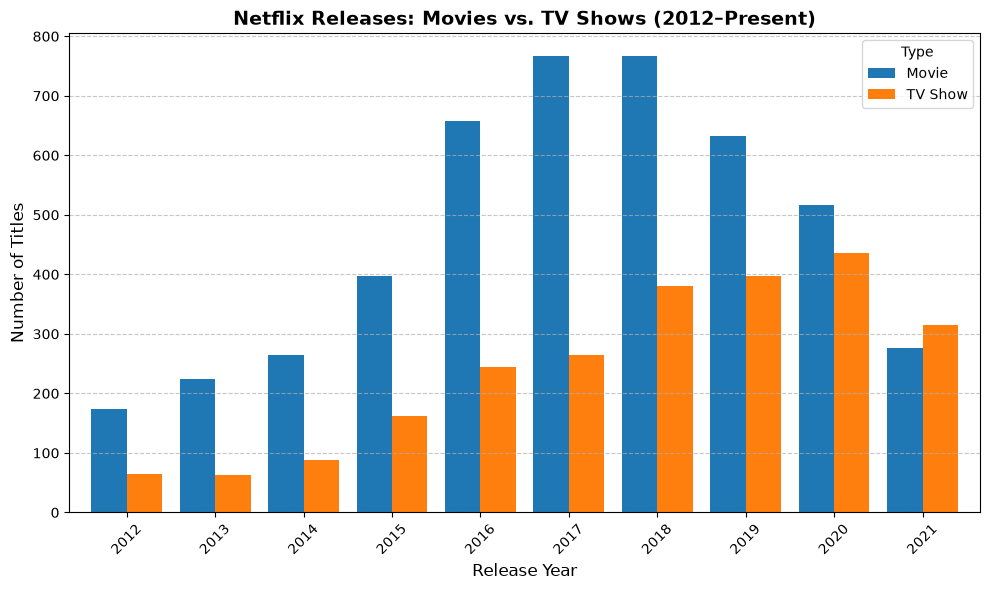

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

recent_df = df[df['release_year'] >= 2012]

trend_data = recent_df.groupby(['release_year', 'type']).size().unstack().fillna(0)

plt.figure(figsize=(10, 6))
trend_data.plot(kind='bar', width=0.8, ax=plt.gca())
plt.title('Netflix Releases: Movies vs. TV Shows (2012–Present)', fontsize=14, fontweight='bold')
plt.xlabel('Release Year', fontsize=12)
plt.ylabel('Number of Titles', fontsize=12)
plt.legend(title='Type')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [5]:
genres_df = df.assign(genre=df['listed_in'].str.split(', ')).explode('genre')

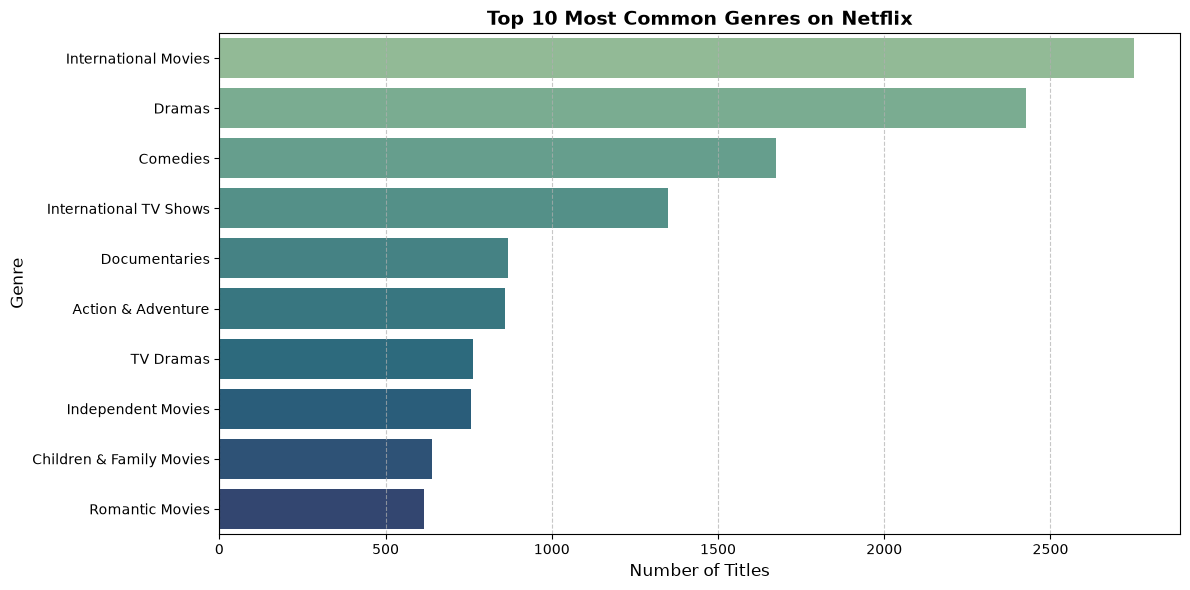

In [6]:

top_genres = genres_df['genre'].value_counts().head(10)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_genres.values, y=top_genres.index, hue=top_genres.index, palette='crest', legend=False)
plt.title('Top 10 Most Common Genres on Netflix', fontsize=14, fontweight='bold')
plt.xlabel('Number of Titles', fontsize=12)
plt.ylabel('Genre', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [ ]:

top_3_list = top_genres.head(3).index.tolist()
top3_df = genres_df[genres_df['genre'].isin(top_3_list) & (genres_df['release_year'] >= 2015)]
genre_trend = top3_df.groupby(['release_year', 'genre']).size().unstack().fillna(0)

plt.figure(figsize=(10, 6))
genre_trend.plot(kind='line', marker='o', linewidth=2.5, ax=plt.gca())
plt.title('Trend of Top 3 Netflix Genres (2015–2021)', fontsize=14, fontweight='bold')
plt.xlabel('Release Year', fontsize=12)
plt.ylabel('Number of Titles Released', fontsize=12)
plt.legend(title='Genre')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [ ]:

print("=== SUMMARY METRICS ===")
print("Total Titles Analyzed:", len(df))
print("Movies Count:", len(df[df['type'] == 'Movie']))
print("TV Shows Count:", len(df[df['type'] == 'TV Show']))
print("Percentage of Movies: {:.2f}%".format((len(df[df['type'] == 'Movie']) / len(df)) * 100))
print("Percentage of TV Shows: {:.2f}%".format((len(df[df['type'] == 'TV Show']) / len(df)) * 100))